# 🔁 실험 E — 모델 v2: "뭘 비춰도 마우스래요"를 고친다

### 왜 v2인가

실험 A 모델(yolo11n, 10종, Open Images, imgsz 640)을 아이폰 웹앱에 넣고 써 본 사용자의 피드백:

> **"뭘 보여 줘도 마우스라고 해요."**

앱 기준 통과율(물건이 있을 때 맞히는 비율)은 0.56이었지만, **물건이 아닐 때 "아니다"라고 하는 능력**은 잰 적이 없다.
앱에서는 이게 더 중요하다 — 아무거나 비춰서 알람이 꺼지면 미션이 의미가 없다.

### 가설 두 가지

| 가설 | 근거 | 이번에 바꾸는 것 |
|---|---|---|
| ① **네거티브를 배운 적이 없다** | 학습 사진은 모두 10종 중 하나가 있는 사진이다. 폰 · 리모컨 · 손처럼 사람이 들고 비출 법한 *다른* 물건을 "아무것도 아님"으로 배운 적이 없다 | **하드 네거티브** 16라벨 사진을 배경으로 넣는다 |
| ② **장면이 다르다** | 학습: 장면 전체 사진을 640으로. 앱: 물건 하나가 크게 가운데에 있는 320 crop | 학습 사진에서 박스마다 **앱처럼 자른 crop**을 만들고, **imgsz 320**으로 학습 |

> 실험 C(지운 박스를 회색으로 칠하기)는 도움이 안 됐으므로 다시 하지 않는다.

### 같이 바꾸는 것

- **새 클래스 3종**: 컵 ☕ · 텀블러 🥤 · 의자 🪑 → 13종 (기존 0~9번은 그대로)
- **약한 클래스 보강**: A에서 낮았던 문 · 신발 · 책은 train 사진을 최대 1000장으로 늘리고, crop을 박스당 3장 만든다
- **클래스별 신뢰도 기준**: 모든 클래스에 0.5 하나를 쓰지 않고, 클래스마다 "잘못 통과 ≤ 2%"가 되는 기준을 고른다
- **A에서 이어서 학습**(warm start): 백본 · 넥 · 박스 갈래는 A의 가중치, 클래스 갈래 마지막 층만 13종으로 새로 초기화

| 단계 | 내용 |
|---|---|
| 0 | 설정 |
| 1 | 클래스 13종 |
| 2 | 데이터 받기 (13종 + 하드 네거티브) |
| 3 | 앱 장면 crop 만들기 + 학습 세트 구성 |
| 4 | 평가용 crop (양성 · 네거티브) |
| 5 | 실험 E 학습 + 학습곡선 |
| 6 | 평가 ① 통과율 ② 잘못 통과율 ③ 무엇이 '마우스'가 되나 |
| 7 | 클래스별 신뢰도 기준 고르기 (tune 절반 → test 절반) |
| 8 | 클래스별 P · R · F1 (앱 crop, 전체 사진 val) |
| 9 | 웹앱 준비 (ONNX 내보내기 · 검증 · 교체 판단) |
| 10 | 결론 |

## 0. 설정

In [1]:
import sys, time, shutil, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cv2, torch
from ultralytics import YOLO
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C, data as D, evaluate as E, crops as P, missioneval as M

DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
DATA, RUNS = ROOT / 'data', ROOT / 'runs'
FULL_DIR = DATA / 'yolo13_full'        # 전체 사진 (긴 변 640으로 줄여 저장)
CROP_DIR = DATA / 'yolo13_crops'       # 앱 장면 crop (학습용)
TRAIN_DIR = DATA / 'yolo13'            # 학습 세트 = 전체 사진 + crop (하드링크로 합침)
EVAL_DIR = DATA / 'eval13'             # 평가용 crop (양성 pos · 네거티브 neg)

PER_TRAIN = {'*': 400, 'door': 1000, 'shoe': 1000, 'book': 1000}   # 약한 3종은 더 많이
PER_VAL = 80
NEG_TRAIN, NEG_VAL = 100, 25           # 네거티브 라벨당 사진 수
WEAK = ['door', 'shoe', 'book']        # A에서 약했던 클래스 → crop 박스당 3장
EPOCHS, PATIENCE, BATCH, IMGSZ = 35, 15, 32, 320   # 60 → 35: 시간 예산 (아래 설명)
NC = len(C.CLASSES13)

A_WEIGHTS = RUNS / 'A_full' / 'weights' / 'best.pt'
assert A_WEIGHTS.exists(), f'{A_WEIGHTS} 가 없어요. 먼저 wakeup_mission.ipynb에서 실험 A를 학습하세요.'

plt.rcParams['font.family'] = 'AppleGothic'; plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.precision', 3)
KO = {c.id: c.ko for c in C.CLASSES13}
print('device:', DEVICE, '| 클래스:', NC)

/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | 클래스: 13


## 1. 클래스 13종

0~9번은 A와 **똑같다** (번호를 바꾸면 A의 가중치를 이어받을 때 헷갈림). 10~12번을 새로 붙인다.

- Open Images에는 **"Tumbler" 라벨이 없다.** 가장 가까운 **"Bottle"**(병)을 텀블러로 쓴다.
  그래서 이 모델의 '텀블러'는 실제로는 "병 모양 음료 용기"를 배운 것이다 (와인병 · 물병 포함).
- 컵은 "Mug"(머그)와 "Coffee cup"(커피잔)을 합친다.

In [2]:
pd.DataFrame([dict(id=c.id, 미션=C.mission_text(c), 키=c.key, OpenImages라벨=', '.join(c.oi_labels),
                   구분='v2 새로' if c.id >= 10 else ('COCO가 알던 것' if c.coco_id is not None else 'A에서 새로'))
              for c in C.CLASSES13])

,id,미션,키,OpenImages라벨,구분
0,0,🖱️ 마우스를 비춰라,mouse,Computer mouse,COCO가 알던 것
1,1,☂️ 우산을 비춰라,umbrella,Umbrella,COCO가 알던 것
2,2,📖 책을 비춰라,book,Book,COCO가 알던 것
3,3,🪥 칫솔을 비춰라,toothbrush,Toothbrush,COCO가 알던 것
4,4,🧢 모자를 비춰라,hat,"Hat, Fedora, Sun hat, Cowboy hat, Sombrero",A에서 새로
5,5,🚪 문을 비춰라,door,Door,A에서 새로
6,6,🧻 휴지를 비춰라,toilet_paper,Toilet paper,A에서 새로
7,7,🧦 양말을 비춰라,sock,Sock,A에서 새로
8,8,👟 신발을 비춰라,shoe,"Footwear, Boot, High heels, Sandal",A에서 새로
9,9,👓 안경을 비춰라,glasses,"Glasses, Sunglasses",A에서 새로


## 2. 데이터 받기 — 13종 + 하드 네거티브

### 하드 네거티브란?

'쉬운' 네거티브는 아무것도 없는 벽 사진이다. 모델은 이미 잘 맞힌다.
**하드 네거티브**는 *목표 물건과 헷갈릴 만한* 다른 물건이다. 사람이 알람을 끄려고 손에 잡히는 대로 비출 법한 것들을 골랐다.

| 들고 비출 법한 것 | 책상 · 부엌 | 몸 |
|---|---|---|
| Mobile phone · Remote control · Pen · Watch · Headphones · Tablet computer | Computer keyboard · Laptop · Box · Pillow · Towel · Plastic bag · Bowl · Spoon · Kitchen utensil | Human hand |

- 이 라벨들의 박스는 **내보내지 않는다** → 그 자리는 "아무것도 아님(배경)"으로 배운다.
- 네거티브 사진에 목표 13종 박스가 있으면 그 박스는 **그대로 쓴다** (예: 노트북 옆 마우스).
- 한계: Open Images는 사진마다 확인한 라벨만 박스를 그린다(**빠진 라벨**). 노트북 사진에 마우스가 있는데 박스가 없으면 그 마우스는 배경으로 배워진다.

In [3]:
t0 = time.time()
ds = {'train': D.load_split('train', PER_TRAIN, classes=C.CLASSES13, name='wakeup13-train'),
      'val': D.load_split('validation', PER_VAL, classes=C.CLASSES13, name='wakeup13-validation')}
neg = {'train': D.load_negatives('train', NEG_TRAIN), 'val': D.load_negatives('validation', NEG_VAL)}
print(f'받기/불러오기 {time.time() - t0:.0f}초')
pd.DataFrame({'13종 사진': {s: len(d) for s, d in ds.items()}, '네거티브 사진': {s: len(d) for s, d in neg.items()}})

받기/불러오기 3초


,13종 사진,네거티브 사진
train,6039,1560
val,658,308


In [4]:
# 데이터셋 → 단순 기록 [dict(filepath, targets=[(cls, x, y, w, h)], negs=[(라벨, x, y, w, h)])]
rec = lambda d: P.records_from_dataset(d, C.OI_TO_KEY13, C.KEYS13, C.NEG_LABELS)
R = {s: rec(d) for s, d in ds.items()}
RN = {s: rec(d) for s, d in neg.items()}
R_train = P.merge_records(R['train'], RN['train'])          # 같은 사진은 한 번만

# 네거티브 라벨별 박스 수 (train 네거티브 사진 기준)
neg_box = pd.Series([lab for r in RN['train'] for lab, *_ in r['negs']]).value_counts()
neg_img_with_target = sum(bool(r['targets']) for r in RN['train'])
print(f'네거티브 사진 {len(RN["train"])}장 중 목표 13종 박스도 있는 사진: {neg_img_with_target}장 (그 박스는 학습에 씀)')
neg_box.rename('박스 수').to_frame().T

네거티브 사진 1560장 중 목표 13종 박스도 있는 사진: 286장 (그 박스는 학습에 씀)


,Human hand,Bowl,Pillow,Box,Towel,Computer keyboard,Laptop,Kitchen utensil,Mobile phone,Plastic bag,Spoon,Pen,Watch,Headphones,Tablet computer,Remote control
박스 수,380,290,266,259,243,222,219,216,210,175,169,168,136,132,126,123


## 3. 앱 장면 crop 만들기 + 학습 세트

앱은 **스캔 틀(정사각형)을 320×320으로 줄여** 모델에 넣는다. 학습 사진에서도 그렇게 잘라 본다.

```
박스 하나 (면적 ≥ 사진의 1%)
 → 박스를 가운데에 두고, 박스 긴 변 / 정사각형 한 변 = fill (0.35 ~ 0.8 사이 무작위)
 → 가운데에서 한 변의 ±10%만큼 무작위로 밀기 (사람은 정확히 가운데에 대지 않는다)
 → 사진 밖으로 나가면 안쪽으로 밀기 → 320×320으로 줄이기
 → 라벨: crop 안에 면적의 40% 이상 보이는 목표 박스 (경계에서 잘라서)
```

- **목표 박스**: 사진 한 장에서 클래스마다 **가장 큰 박스 하나**를 중심으로 1장, 약한 3종(문 · 신발 · 책)은 **3장** (fill · 위치가 서로 다르게)
  - 처음엔 박스마다 만들었더니 책장 사진 하나에서 책 crop이 수십 장씩 나와 crop이 27,832장(책만 9,879장)이 됐다.
    한 에폭에 약 7분 → 60에폭이면 7시간이라 시간 예산(2.5시간)을 넘는다. 그래서 클래스마다 가장 큰 박스 하나로 줄이고(앱도 큰 물건 하나를 본다) 에폭을 35로 줄였다.
- **네거티브 박스**: 네거티브 사진에서 큰 박스부터 사진당 최대 3개, 각 1장 → 라벨은 그 안의 목표 박스뿐 (보통 없음 = 배경)
- 전체 사진도 그대로 쓴다 (긴 변 640으로 줄여 저장 → 320 학습 때 읽기가 빠름)

**학습 세트 = 전체 사진(13종 + 네거티브) + crop 전부.** val은 13종 전체 사진 그대로 (mAP용).

In [5]:
t0 = time.time()
neg_paths = set(neg['train'].values('filepath'))
# 네거티브 crop은 네거티브 사진에서만 (13종 사진 속 손 · 폰까지 자르면 네거티브가 너무 많아짐)
R_crop = [r if r['filepath'] in neg_paths else {**r, 'negs': []} for r in R_train]
weak_ids = {C.BY_KEY13[k].id: 3 for k in WEAK}

n_full_train = P.export_full(R_train, FULL_DIR, 'train')
n_full_val = P.export_full(R['val'], FULL_DIR, 'val')
crops_train = P.export_crops(R_crop, CROP_DIR, 'train', seed=0, n_per_class=weak_ids, neg_per_image=3,
                             pos_per_class=1, keys=C.KEYS13)

TRAIN_DONE = TRAIN_DIR / 'labels' / 'train.done'
if not TRAIN_DONE.exists():
    print('합친 학습 사진:', P.link_split([FULL_DIR, CROP_DIR], TRAIN_DIR, 'train'))
    print('val 사진:', P.link_split([FULL_DIR], TRAIN_DIR, 'val'))
    TRAIN_DONE.touch()
P.write_yaml(TRAIN_DIR, C.KEYS13)
YAML = TRAIN_DIR / 'dataset.yaml'
print(f'{time.time() - t0:.0f}초')

comp = pd.DataFrame({
    '전체 사진 · 13종': [sum(r['filepath'] not in neg_paths for r in R_train)],
    '전체 사진 · 네거티브': [len(neg_paths & {r['filepath'] for r in R_train})],
    'crop · 목표 박스': [(crops_train['kind'] == 'pos').sum()],
    'crop · 네거티브 박스': [(crops_train['kind'] == 'neg').sum()],
}, index=['train'])
comp['합계'] = comp.sum(axis=1)
comp

합친 학습 사진: 20231


val 사진: 658
113초


,전체 사진 · 13종,전체 사진 · 네거티브,crop · 목표 박스,crop · 네거티브 박스,합계
train,5875,1560,10473,2323,20231


In [6]:
# 클래스별 학습 라벨 (전체 사진 + crop, 겹친 박스 제거 후)
cnt = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES13]})
for name, d in [('전체 사진', FULL_DIR), ('crop', CROP_DIR)]:
    t = D.label_counts(d, 'train', C.CLASSES13).set_index('id')
    cnt[f'{name} 사진'] = t['사진']; cnt[f'{name} 박스'] = t['박스']
cnt['val 박스'] = D.label_counts(FULL_DIR, 'val', C.CLASSES13).set_index('id')['박스']
cnt

,클래스,전체 사진 사진,전체 사진 박스,crop 사진,crop 박스,val 박스
0,마우스,402,457,446,479,24
1,우산,406,863,415,650,35
2,책,1025,5265,3092,9055,626
3,칫솔,113,201,113,183,16
4,모자,425,738,501,602,134
5,문,1008,1454,2889,3591,108
6,휴지,226,368,185,251,5
7,양말,400,829,679,1116,17
8,신발,1080,4926,1449,2682,320
9,안경,537,1125,545,686,123


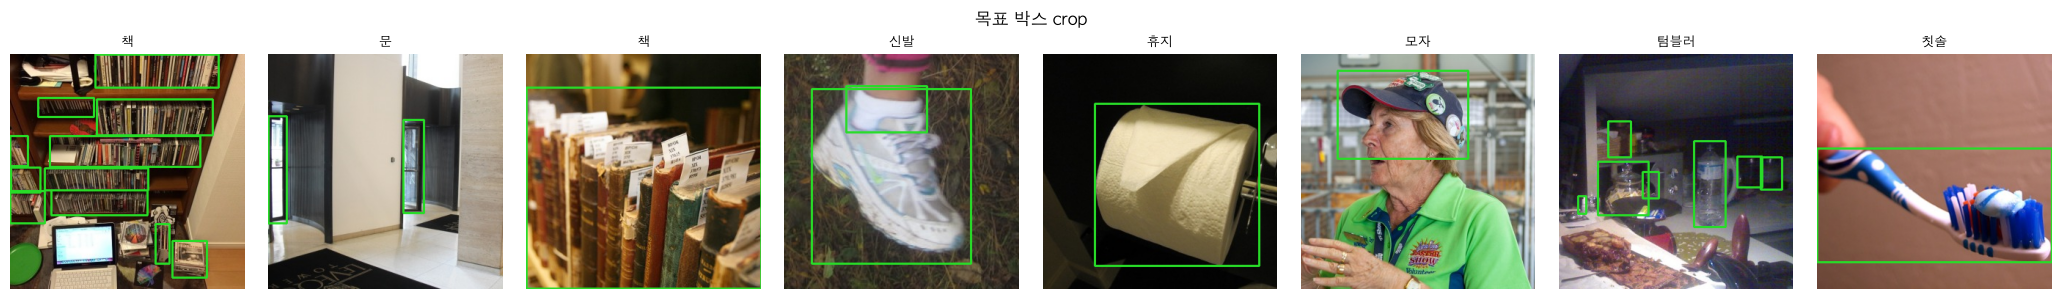

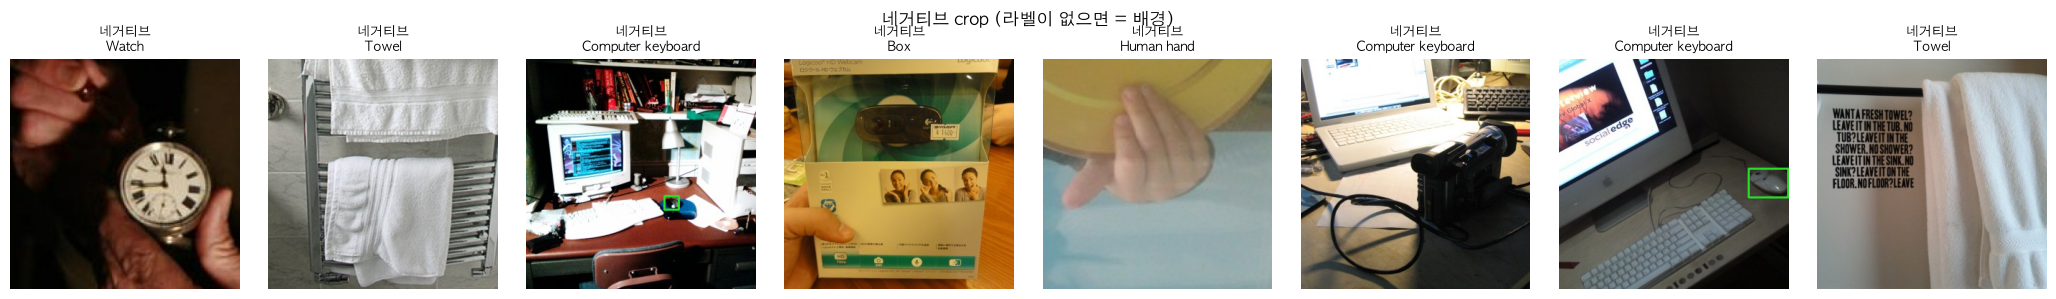

In [7]:
# crop 예시: 위 = 목표 박스 crop (초록 = 라벨), 아래 = 네거티브 crop
def show_crops(df, n=8, title=''):
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 3))
    for ax, (_, r) in zip(axes, df.head(n).iterrows()):
        img = cv2.imread(str(CROP_DIR / 'images' / 'train' / r['file']))[:, :, ::-1].copy()
        for line in (CROP_DIR / 'labels' / 'train' / r['file'].replace('.jpg', '.txt')).read_text().splitlines():
            k, cx, cy, w, h = line.split(); cx, cy, w, h = (float(v) * 320 for v in (cx, cy, w, h))
            cv2.rectangle(img, (int(cx - w / 2), int(cy - h / 2)), (int(cx + w / 2), int(cy + h / 2)), (40, 220, 40), 2)
        ax.imshow(img); ax.axis('off')
        ax.set_title(KO[int(r['target'])] if r['kind'] == 'pos' else f"네거티브\n{r['center']}", fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_crops(crops_train[crops_train.kind == 'pos'].sample(8, random_state=1), title='목표 박스 crop')
show_crops(crops_train[crops_train.kind == 'neg'].sample(8, random_state=1), title='네거티브 crop (라벨이 없으면 = 배경)')

## 4. 평가용 crop

학습에 쓰지 않은 **validation**에서 앱처럼 자른다. 무작위 없이 박스를 가운데에, fill 0.6 (실험 C와 같은 방식).

| 종류 | 출처 | 묻는 것 |
|---|---|---|
| **양성 crop** | 13종 val 사진의 목표 박스 (면적 ≥ 1%) | 미션 물건을 비추면 **통과하나?** |
| **네거티브 crop** | 네거티브 val 사진(라벨당 25장)의 네거티브 박스 (사진당 최대 3개) | 다른 물건을 비추면 **안 통과하나?** |

- 네거티브 crop 안에 목표 박스가 40% 이상 보이면(예: 노트북 crop 속 마우스) 그건 '틀린 통과'가 아니므로 **뺀다.**
- 사진 이름의 해시로 **tune / test 절반**을 나눈다 (같은 사진의 crop은 같은 쪽) → 7절에서 기준은 tune으로 고르고 test로 잰다.
- 양성 crop은 원본 val(청소 안 함)에서 만들었으므로, 실험 C의 앱 기준 통과율(청소한 val)과 숫자가 다르다.
- Open Images validation에는 원래 장수가 적은 클래스가 있다 (휴지 박스 5개, 칫솔 · 양말 · 마우스 20여 개). 이런 클래스의 통과율은 **몇 장에 크게 흔들리므로** 장수와 같이 본다.

In [8]:
ev_pos = P.export_crops(R['val'], EVAL_DIR, 'pos', fixed_fill=0.6, neg=False, keys=C.KEYS13)
ev_neg_all = P.export_crops(RN['val'], EVAL_DIR, 'neg', fixed_fill=0.6, pos=False)
ev_neg = ev_neg_all[ev_neg_all['n_rows'] == 0].reset_index(drop=True)
print(f'양성 crop {len(ev_pos)}장 | 네거티브 crop {len(ev_neg_all)}장 중 목표 박스가 보이는 {len(ev_neg_all) - len(ev_neg)}장 제외 → {len(ev_neg)}장')
pd.DataFrame({'양성 crop': ev_pos.groupby('half').size(), '네거티브 crop': ev_neg.groupby('half').size()})

양성 crop 1526장 | 네거티브 crop 461장 중 목표 박스가 보이는 39장 제외 → 422장


,양성 crop,네거티브 crop
half,,
test,747,209
tune,779,213


In [9]:
pd.DataFrame({'양성 crop 수': ev_pos.groupby('target').size().rename(index=KO)}).T

target,마우스,우산,책,칫솔,모자,문,휴지,양말,신발,안경,컵,텀블러,의자
양성 crop 수,23,37,454,18,188,108,3,25,101,154,133,133,149


## 5. 실험 E 학습

| 설정 | 실험 A | **실험 E** |
|---|---|---|
| 시작 가중치 | yolo11n.pt (COCO) | **A의 best.pt** (클래스 층만 13종으로 새로) |
| 데이터 | 10종 전체 사진 | 13종 전체 사진 + **네거티브** + **앱 장면 crop** |
| imgsz | 640 | **320** (앱 입력과 같음) |
| 에폭 · patience | 50 · 10 | 35 · 15 (시간 예산 때문에 60에서 줄임) |
| batch | 16 | 32 |

증강(모자이크 · HSV · 좌우 뒤집기 등)은 Ultralytics 기본값 그대로다.

In [10]:
E_DIR = RUNS / 'E_v2'
done = E_DIR / 'done'                 # 학습이 끝까지 돌았다는 표시 (중단된 학습의 best.pt는 재사용하지 않음)
if done.exists():
    print('E_v2 이미 학습됨 → 건너뜀')
else:
    t0 = time.time()
    YOLO(A_WEIGHTS).train(data=str(YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
                          device=DEVICE, project=str(RUNS), name='E_v2', exist_ok=True,
                          seed=0, workers=8, plots=True)
    done.touch()
    print(f'학습 시간: {(time.time() - t0) / 60:.1f}분')
E_WEIGHTS = E_DIR / 'weights' / 'best.pt'
r = pd.read_csv(E_DIR / 'results.csv'); r.columns = r.columns.str.strip()
print(f"에폭 {len(r)} · 가장 좋은 val mAP50 {r['metrics/mAP50(B)'].max():.3f} (에폭 {int(r.loc[r['metrics/mAP50(B)'].idxmax(), 'epoch'])}) · 총 {r['time'].iloc[-1] / 60:.0f}분")

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 MPS (Apple M4 Pro)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo13/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/A_full/weights/best.pt, momentum=0.937, mosaic=1.0,

Overriding model.yaml nc=10 with nc=13



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (232 outputs left out)

                 chair         80        223       0.39      0.118      0.118     0.0623


Speed: 0.0ms preprocess, 1.8ms inference, 0.0ms loss, 1.4ms postprocess per image


Results saved to /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/E_v2


학습 시간: 124.7분
에폭 35 · 가장 좋은 val mAP50 0.533 (에폭 30) · 총 124분


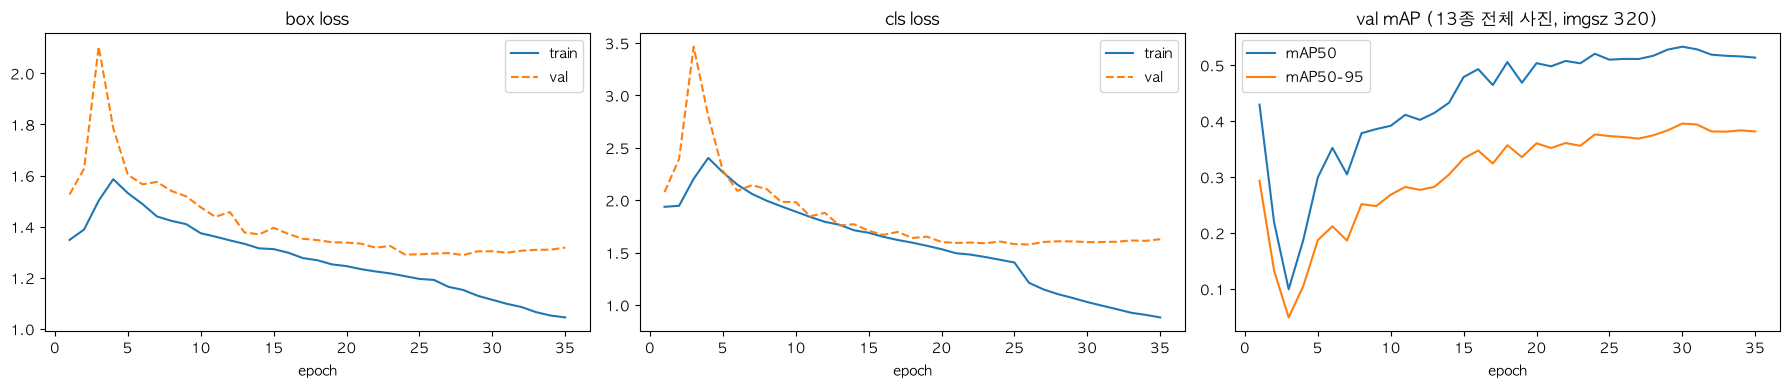

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(r['epoch'], r['train/box_loss'], label='train'); axes[0].plot(r['epoch'], r['val/box_loss'], '--', label='val')
axes[1].plot(r['epoch'], r['train/cls_loss'], label='train'); axes[1].plot(r['epoch'], r['val/cls_loss'], '--', label='val')
axes[2].plot(r['epoch'], r['metrics/mAP50(B)'], label='mAP50'); axes[2].plot(r['epoch'], r['metrics/mAP50-95(B)'], label='mAP50-95')
for ax, t in zip(axes, ['box loss', 'cls loss', 'val mAP (13종 전체 사진, imgsz 320)']):
    ax.set_title(t); ax.legend(); ax.set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 6. 평가 — 앱 규칙으로

앱과 **같은 규칙**: 신뢰도 기준 이상 · NMS 0.45 → 긴 변이 틀의 40% 이상인 박스 중 가장 큰 것 = **주인공 박스**.

- **통과율**(양성 crop): 주인공 박스의 클래스 = 정답 클래스인 비율
- **잘못 통과율**(네거티브 crop): 주인공 박스가 클래스 k인 비율 = "미션이 k일 때 이 물건을 비추면 **잘못 통과**"
- **아무거나**: 주인공 박스가 어떤 클래스든 있는 비율 (미션이 무엇이든 위험)

예측은 가장 낮은 기준(0.4)으로 **한 번만** 하고 박스를 저장해 둔다. 기준을 올리는 것은 저장한 박스를 거르기만 하면 된다
(NMS는 같은 클래스 안에서 점수 높은 박스부터 남기므로, 거른 결과 = 그 기준으로 다시 예측한 결과).

A는 학습한 imgsz는 640이지만 앱에서는 320으로 돌므로 **둘 다 320으로** 잰다. A는 컵 · 텀블러 · 의자를 모른다.

In [12]:
models = {'A': YOLO(A_WEIGHTS), 'E': YOLO(E_WEIGHTS)}
t0 = time.time()
dets = {}
for mn, m in models.items():
    dets[mn] = {'pos': M.predict_dets(m, ev_pos['file'], EVAL_DIR / 'images' / 'pos', conf=min(M.GRID), imgsz=320, device=DEVICE),
                'neg': M.predict_dets(m, ev_neg['file'], EVAL_DIR / 'images' / 'neg', conf=min(M.GRID), imgsz=320, device=DEVICE)}
print(f'예측 {time.time() - t0:.0f}초')

FLAT = E.CONF   # 0.5 = 지금 앱의 기준
main = {mn: {k: M.mains(v, FLAT) for k, v in d.items()} for mn, d in dets.items()}
ev_pos['target'] = ev_pos['target'].astype(int)

예측 11초


In [13]:
# ① 양성 통과율 (모든 평가 crop, 기준 0.5)
tbl = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES13]}, index=range(NC))
tbl['장수'] = ev_pos.groupby('target').size().reindex(range(NC)).fillna(0).astype(int)
for mn in models:
    passed = main[mn]['pos'] == ev_pos['target'].to_numpy()
    tbl[f'{mn} 통과율'] = pd.Series(passed).groupby(ev_pos['target']).mean().reindex(range(NC))
tbl.loc[range(10, 13), 'A 통과율'] = np.nan          # A는 모르는 클래스
old = ev_pos['target'] < 10
summ = {}
for mn in models:
    passed = main[mn]['pos'] == ev_pos['target'].to_numpy()
    summ[mn] = dict(old10=passed[old].mean(), all13=passed.mean())
tbl.loc['기존 10종'] = ['기존 10종', old.sum(), summ['A']['old10'], summ['E']['old10']]
tbl.loc['13종 전체'] = ['13종 전체', len(ev_pos), np.nan, summ['E']['all13']]
tbl['E-A'] = tbl['E 통과율'] - tbl['A 통과율']
tbl.round(2)

,클래스,장수,A 통과율,E 통과율,E-A
0,마우스,23,1.00,0.96,-0.04
1,우산,37,0.76,0.59,-0.16
2,책,454,0.64,0.83,0.19
3,칫솔,18,0.56,0.61,0.06
4,모자,188,0.76,0.81,0.05
5,문,108,0.27,0.59,0.32
6,휴지,3,0.67,1.00,0.33
7,양말,25,0.76,0.76,0.00
8,신발,101,0.35,0.50,0.15
9,안경,154,0.68,0.51,-0.17


In [14]:
# ② 잘못 통과율 (네거티브 crop, 기준 0.5): 클래스 k로 잡힌 비율
fp_tbl = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES13]}, index=range(NC))
for mn in models:
    fp_tbl[f'{mn} 잘못 통과율'] = M.false_pass(main[mn]['neg'], NC)
fp_tbl.loc[range(10, 13), 'A 잘못 통과율'] = np.nan
fp_tbl.loc['아무거나'] = ['아무 클래스든'] + [(main[mn]['neg'] >= 0).mean() for mn in models]
print('네거티브 crop', len(ev_neg), '장')
fp_tbl.round(3)

네거티브 crop 422 장


,클래스,A 잘못 통과율,E 잘못 통과율
0,마우스,0.092,0.009
1,우산,0.000,0.000
2,책,0.007,0.050
3,칫솔,0.005,0.007
4,모자,0.000,0.002
5,문,0.007,0.005
6,휴지,0.043,0.012
7,양말,0.031,0.002
8,신발,0.017,0.012
9,안경,0.021,0.000


In [15]:
# ③ 무엇이 무엇으로 잡히나: 네거티브 라벨(줄) × 주인공 박스 클래스(칸), 비율. '-' = 안 잡힘 (= 올바른 거부)
def neg_crosstab(m):
    pred = pd.Series([KO[k] if k >= 0 else '-' for k in m], name='잡힌 것')
    t = pd.crosstab(ev_neg['center'].rename('네거티브'), pred, normalize='index')
    cols = ['-'] + [c.ko for c in C.CLASSES13 if c.ko in t.columns]
    return t[cols].round(2)

for mn in models:
    print(f'모델 {mn} (기준 0.5)')
    t = neg_crosstab(main[mn]['neg'])
    display(t.style.format('{:.2f}').background_gradient(cmap='Reds', axis=None, vmin=0, vmax=1, subset=[c for c in t.columns if c != '-']))

모델 A (기준 0.5)


잡힌 것,-,마우스,책,칫솔,문,휴지,양말,신발,안경
네거티브,,,,,,,,,
Bowl,0.76,0.07,0.00,0.00,0.00,0.03,0.07,0.07,0.00
Box,0.66,0.03,0.00,0.00,0.03,0.11,0.11,0.03,0.05
Computer keyboard,0.96,0.04,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Headphones,0.76,0.16,0.00,0.00,0.00,0.00,0.00,0.00,0.08
Human hand,0.98,0.00,0.00,0.00,0.00,0.00,0.02,0.00,0.00
Kitchen utensil,0.71,0.14,0.00,0.00,0.00,0.00,0.00,0.07,0.07
Laptop,0.91,0.07,0.00,0.00,0.00,0.02,0.00,0.00,0.00
Mobile phone,0.65,0.29,0.03,0.00,0.00,0.00,0.00,0.00,0.03
Pen,0.83,0.07,0.03,0.07,0.00,0.00,0.00,0.00,0.00


모델 E (기준 0.5)


잡힌 것,-,마우스,책,칫솔,모자,문,휴지,양말,신발,컵,텀블러
네거티브,,,,,,,,,,,
Bowl,0.93,0.00,0.00,0.00,0.03,0.00,0.00,0.00,0.00,0.03,0.00
Box,0.87,0.00,0.13,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Computer keyboard,0.93,0.00,0.00,0.04,0.00,0.00,0.00,0.00,0.00,0.00,0.04
Headphones,0.88,0.04,0.04,0.00,0.00,0.00,0.00,0.00,0.00,0.04,0.00
Human hand,0.87,0.00,0.04,0.00,0.00,0.00,0.02,0.00,0.07,0.00,0.00
Kitchen utensil,0.86,0.04,0.07,0.00,0.00,0.00,0.00,0.00,0.04,0.00,0.00
Laptop,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Mobile phone,0.94,0.03,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Pen,0.67,0.00,0.20,0.03,0.00,0.07,0.00,0.00,0.00,0.00,0.03


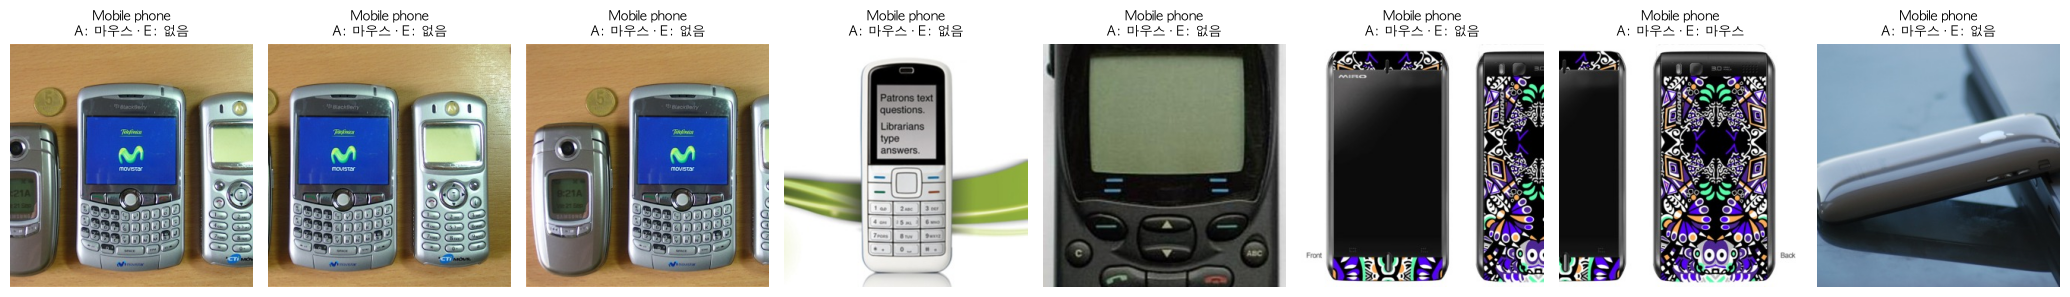

In [16]:
# '마우스'로 잡힌 네거티브 예시 (A)
mouse_id = C.BY_KEY13['mouse'].id
idx = np.where(main['A']['neg'] == mouse_id)[0][:8]
if len(idx):
    fig, axes = plt.subplots(1, len(idx), figsize=(2.6 * len(idx), 3), squeeze=False)
    for ax, i in zip(axes[0], idx):
        f = ev_neg.loc[i, 'file']
        ax.imshow(cv2.imread(str(EVAL_DIR / 'images' / 'neg' / f))[:, :, ::-1]); ax.axis('off')
        e_k = main['E']['neg'][i]
        ax.set_title(f"{ev_neg.loc[i, 'center']}\nA: 마우스 · E: {KO[e_k] if e_k >= 0 else '없음'}", fontsize=9)
    plt.tight_layout(); plt.show()

## 7. 클래스별 신뢰도 기준 고르기

기준 하나(0.5)를 모든 클래스에 쓰면, 네거티브를 자주 끌어당기는 클래스(예: 마우스)가 문제를 만든다.
그래서 **클래스마다** 기준을 고른다.

1. 평가 crop을 사진 해시로 **tune / test** 반씩 나눈다 (4절)
2. **tune 절반의 네거티브 crop**에서, 클래스 k마다 {0.40, 0.45, …, 0.90} 중
   **잘못 통과율 ≤ 2%** 인 **가장 낮은** 기준을 고른다 (없으면 0.9)
   - 단순화: 기준 t의 잘못 통과율은 모든 클래스에 t를 똑같이 썼을 때로 잰다
3. **test 절반**에서 0.5 하나 vs 클래스별 기준을 비교한다 (기준을 고를 때 안 본 사진)

비교를 위해 A에도 같은 방법으로 기준을 골라 본다 (기준만 바꿔서 A를 고칠 수 있나?).

In [17]:
tune_n = (ev_neg['half'] == 'tune').to_numpy()
test_n = ~tune_n
test_p = (ev_pos['half'] == 'test').to_numpy()
thr = {}
for mn in models:
    neg_tune = [d for d, t in zip(dets[mn]['neg'], tune_n) if t]
    nc = 10 if mn == 'A' else NC
    thr[mn] = M.choose_thresholds(neg_tune, nc)
thr_tbl = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES13],
                        'A 기준': [thr['A'].get(k) for k in range(NC)],
                        'E 기준': [thr['E'][k] for k in range(NC)]})
thr_tbl

,클래스,A 기준,E 기준
0,마우스,0.90,0.40
1,우산,0.40,0.40
2,책,0.40,0.65
3,칫솔,0.40,0.40
4,모자,0.40,0.40
5,문,0.40,0.40
6,휴지,0.75,0.40
7,양말,0.70,0.40
8,신발,0.40,0.40
9,안경,0.45,0.40


In [18]:
# test 절반에서: 0.5 하나 vs 클래스별 기준
def evaluate_half(mn, t):
    pos_m = M.mains([d for d, k in zip(dets[mn]['pos'], test_p) if k], t)
    neg_m = M.mains([d for d, k in zip(dets[mn]['neg'], test_n) if k], t)
    y = ev_pos['target'].to_numpy()[test_p]
    o = y < 10
    return dict(통과율_기존10종=(pos_m == y)[o].mean(),
                통과율_13종=(pos_m == y).mean() if mn == 'E' else np.nan,
                잘못통과_아무거나=(neg_m >= 0).mean(),
                잘못통과_마우스=(neg_m == mouse_id).mean(),
                잘못통과_클래스최대=M.false_pass(neg_m, NC).max()), pos_m, neg_m

setting = {'A · 0.5 (지금 앱)': ('A', FLAT), 'A · 클래스별': ('A', thr['A']),
           'E · 0.5': ('E', FLAT), 'E · 클래스별': ('E', thr['E'])}
half_res, half_main = {}, {}
for name, (mn, t) in setting.items():
    half_res[name], *half_main[name] = evaluate_half(mn, t)
print(f"test 절반: 양성 {test_p.sum()}장 · 네거티브 {test_n.sum()}장")
pd.DataFrame(half_res).T.round(3)

test 절반: 양성 747장 · 네거티브 209장


,통과율_기존10종,통과율_13종,잘못통과_아무거나,잘못통과_마우스,잘못통과_클래스최대
A · 0.5 (지금 앱),0.617,NaN,0.220,0.100,0.100
A · 클래스별,0.631,NaN,0.124,0.014,0.033
E · 0.5,0.722,0.692,0.153,0.010,0.067
E · 클래스별,0.696,0.687,0.153,0.014,0.033


In [19]:
# 클래스별 (test 절반): 통과율 · 잘못 통과율
y_test = ev_pos['target'].to_numpy()[test_p]
per = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES13]}, index=range(NC))
for name in ['A · 0.5 (지금 앱)', 'E · 0.5', 'E · 클래스별']:
    pos_m, neg_m = half_main[name]
    per[f'통과 {name}'] = pd.Series(pos_m == y_test).groupby(y_test).mean().reindex(range(NC))
    per[f'잘못통과 {name}'] = M.false_pass(neg_m, NC)
per.loc[range(10, 13), ['통과 A · 0.5 (지금 앱)', '잘못통과 A · 0.5 (지금 앱)']] = np.nan
per.round(2)

,클래스,통과 A · 0.5 (지금 앱),잘못통과 A · 0.5 (지금 앱),통과 E · 0.5,잘못통과 E · 0.5,통과 E · 클래스별,잘못통과 E · 클래스별
0,마우스,1.00,0.10,0.94,0.01,0.94,0.01
1,우산,0.64,0.00,0.36,0.00,0.43,0.00
2,책,0.62,0.01,0.84,0.07,0.73,0.03
3,칫솔,0.55,0.00,0.73,0.01,0.91,0.01
4,모자,0.76,0.00,0.83,0.00,0.83,0.00
5,문,0.34,0.00,0.62,0.00,0.68,0.01
6,휴지,1.00,0.02,1.00,0.02,1.00,0.03
7,양말,0.76,0.02,0.88,0.00,0.88,0.01
8,신발,0.33,0.02,0.52,0.02,0.55,0.02
9,안경,0.68,0.03,0.47,0.00,0.46,0.00


## 8. 클래스별 Precision · Recall · F1

### 8-1. 앱 crop 기준 (test 절반)

crop 하나 = 문제 하나, 답 = 주인공 박스의 클래스(없으면 '없음'). 네거티브 crop의 정답은 '없음'.

- **Recall(재현율)** = 클래스 k crop 중 k로 맞힌 비율 = 통과율
- **Precision(정밀도)** = k라고 답한 것 중 진짜 k인 비율 → 다른 물건(네거티브 · 다른 클래스)을 k라고 하면 낮아진다
- **F1** = 2PR / (P + R)

> 이 Precision은 평가 세트의 양성 : 네거티브 비율에 따라 달라진다 (실제 사용 환경의 비율과 다를 수 있음).

In [20]:
y_all = np.concatenate([y_test, -np.ones(test_n.sum(), int)])
prf = {}
for name in ['A · 0.5 (지금 앱)', 'E · 0.5', 'E · 클래스별']:
    pos_m, neg_m = half_main[name]
    prf[name] = M.prf(y_all, np.concatenate([pos_m, neg_m]), NC)
prf_tbl = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES13]}, index=range(NC))
for name, t in prf.items():
    for col in ['P', 'R', 'F1']:
        prf_tbl[f'{col} {name}'] = t[col]
prf_tbl.loc[range(10, 13), [c for c in prf_tbl.columns if 'A ·' in c]] = np.nan
prf_tbl['F1 변화 (E 클래스별 - A)'] = prf_tbl['F1 E · 클래스별'] - prf_tbl['F1 A · 0.5 (지금 앱)']
prf_tbl.round(2)

,클래스,P A · 0.5 (지금 앱),R A · 0.5 (지금 앱),F1 A · 0.5 (지금 앱),P E · 0.5,R E · 0.5,F1 E · 0.5,P E · 클래스별,R E · 클래스별,F1 E · 클래스별,F1 변화 (E 클래스별 - A)
0,마우스,0.39,1.00,0.56,0.77,0.94,0.85,0.65,0.94,0.77,0.21
1,우산,0.90,0.64,0.75,0.62,0.36,0.45,0.55,0.43,0.48,-0.27
2,책,0.97,0.62,0.76,0.87,0.84,0.85,0.93,0.73,0.82,0.06
3,칫솔,0.75,0.55,0.63,0.73,0.73,0.73,0.77,0.91,0.83,0.20
4,모자,0.82,0.76,0.79,0.77,0.83,0.80,0.78,0.83,0.80,0.01
5,문,0.94,0.34,0.50,0.97,0.62,0.76,0.94,0.68,0.79,0.29
6,휴지,0.11,1.00,0.20,0.12,1.00,0.22,0.06,1.00,0.12,-0.08
7,양말,0.34,0.76,0.47,0.54,0.88,0.67,0.47,0.88,0.61,0.14
8,신발,0.71,0.33,0.45,0.89,0.52,0.65,0.89,0.55,0.68,0.23
9,안경,0.73,0.68,0.71,0.95,0.47,0.63,0.85,0.46,0.60,-0.11


### 8-2. 전체 사진 val (Ultralytics 지표)

Ultralytics `val()`의 클래스별 P · R(모든 클래스 평균 F1이 가장 큰 신뢰도에서) → **F1 = 2PR / (P + R)**, 그리고 mAP50.

| 줄 | 모델 | val | imgsz |
|---|---|---|---|
| A@640 | A | 10종 val (`data/yolo`) | 640 (A가 학습한 크기) |
| A@320 | A | 10종 val | 320 (앱 크기) |
| E@320 (10종 val) | E | **같은** 10종 val 사진 | 320 |
| E@320 (13종 val) | E | 13종 val (`data/yolo13`) | 320 |

> E의 mAP는 imgsz 320, A의 원래 mAP는 640에서 잰 것이라 **그대로 비교할 수 없다.** 같은 사진 · 같은 크기(320)인 A@320과 E@320(10종 val)을 비교한다.

In [21]:
OLD_VAL = DATA / 'yolo13_oldval.yaml'      # 10종 val 사진을 13종 이름표로 (E 평가용; 라벨 번호 0~9는 같음)
OLD_VAL.write_text(f"path: {(DATA / 'yolo').resolve()}\ntrain: images/val\nval: images/val\nnames:\n" +
                   ''.join(f'  {i}: {k}\n' for i, k in enumerate(C.KEYS13)))
runs_val = [('A@640', 'A', DATA / 'yolo' / 'dataset.yaml', 640), ('A@320', 'A', DATA / 'yolo' / 'dataset.yaml', 320),
            ('E@320 (10종 val)', 'E', OLD_VAL, 320), ('E@320 (13종 val)', 'E', YAML, 320)]
f1_tbl = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES13] + ['전체(mAP50)']}, index=list(range(NC)) + ['mAP50'])
map_tbl = {}
for name, mn, yaml, sz in runs_val:
    m = models[mn].val(data=str(yaml), imgsz=sz, batch=32, device=DEVICE, project=str(RUNS),
                       name=f"E_eval_{name.replace('@', '_').replace(' ', '').replace('(', '_').replace(')', '')}",
                       exist_ok=True, plots=False, verbose=False)
    t = E.per_class_table(m, C.KEYS13 if mn == 'E' else C.KEYS).set_index('id')
    f1 = 2 * t['P'] * t['R'] / (t['P'] + t['R']).replace(0, np.nan)
    f1_tbl[f'F1 {name}'] = f1.reindex(range(NC)).tolist() + [m.box.map50]
    map_tbl[name] = t['mAP50'].reindex(range(NC))
f1_tbl['F1 변화 (E-A, 320, 같은 사진)'] = f1_tbl['F1 E@320 (10종 val)'] - f1_tbl['F1 A@320']
display(f1_tbl.round(3))
pd.DataFrame(map_tbl).assign(클래스=[c.ko for c in C.CLASSES13]).set_index('클래스').round(3).rename(columns=lambda c: f'mAP50 {c}')

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 MPS (Apple M4 Pro)


YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 695.9±223.0 MB/s, size: 205.5 KB)



val: Scanning /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo/labels/val... 432 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 432/432 4.5Kit/s 0.1s

val: New cache created: /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo/labels/val.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.6it/s 5.4s

... (22 outputs left out)

                   all        658       1871      0.671       0.46      0.529      0.392


Speed: 0.0ms preprocess, 1.5ms inference, 0.0ms loss, 1.5ms postprocess per image


,클래스,F1 A@640,F1 A@320,F1 E@320 (10종 val),F1 E@320 (13종 val),"F1 변화 (E-A, 320, 같은 사진)"
0,마우스,0.765,0.729,0.805,0.794,0.075
1,우산,0.638,0.616,0.654,0.674,0.038
2,책,0.383,0.359,0.348,0.302,-0.011
3,칫솔,0.834,0.812,0.624,0.595,-0.187
4,모자,0.649,0.555,0.676,0.606,0.121
5,문,0.345,0.313,0.418,0.412,0.105
6,휴지,0.869,0.755,0.704,0.671,-0.050
7,양말,0.441,0.331,0.555,0.581,0.224
8,신발,0.402,0.387,0.271,0.203,-0.116
9,안경,0.705,0.632,0.638,0.583,0.006


,mAP50 A@640,mAP50 A@320,mAP50 E@320 (10종 val),mAP50 E@320 (13종 val)
클래스,,,,
마우스,0.869,0.851,0.890,0.845
우산,0.699,0.697,0.678,0.656
책,0.329,0.258,0.251,0.251
칫솔,0.848,0.945,0.751,0.685
모자,0.714,0.592,0.657,0.655
문,0.363,0.268,0.372,0.392
휴지,0.825,0.755,0.673,0.626
양말,0.460,0.470,0.651,0.646
신발,0.429,0.303,0.268,0.270


## 9. 웹앱 준비

### 교체 조건 (미리 정함)

E를 앱에 넣는 것은 7절 **test 절반**에서 `E · 클래스별`이 `A · 0.5 (지금 앱)`보다

1. **잘못 통과율(아무거나)이 낮고**,
2. **기존 10종 통과율이 0.05보다 많이 떨어지지 않을 때**만이다.

조건을 만족하면 ONNX(imgsz 320, opset 12, NMS 없음)로 내보내 **검증**한 뒤 `docs/model.onnx`와 `docs/classes.js`(클래스별 `conf` 포함)를 바꾼다.
웹앱(`docs/app.js`)은 가장 낮은 `conf`로 decode → NMS → 박스마다 그 클래스의 `conf`로 거른 뒤 주인공 박스를 고른다 (7절 계산과 같음).

In [22]:
a, e = half_res['A · 0.5 (지금 앱)'], half_res['E · 클래스별']
cond1 = e['잘못통과_아무거나'] < a['잘못통과_아무거나']
cond2 = e['통과율_기존10종'] >= a['통과율_기존10종'] - 0.05
REPLACE = bool(cond1 and cond2)
print(f"① 잘못 통과(아무거나): A {a['잘못통과_아무거나']:.3f} → E {e['잘못통과_아무거나']:.3f}  {'✅' if cond1 else '❌'}")
print(f"② 기존 10종 통과율:    A {a['통과율_기존10종']:.3f} → E {e['통과율_기존10종']:.3f}  {'✅' if cond2 else '❌'} (허용: -0.05)")
print('→ 앱 모델 교체:', REPLACE)

① 잘못 통과(아무거나): A 0.220 → E 0.153  ✅
② 기존 10종 통과율:    A 0.617 → E 0.696  ✅ (허용: -0.05)
→ 앱 모델 교체: True


In [23]:
import onnxruntime as ort
onnx_path = Path(models['E'].export(format='onnx', imgsz=320, opset=12, simplify=True, dynamic=False, nms=False))
sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
print('입력:', sess.get_inputs()[0].shape, '| 출력:', sess.get_outputs()[0].shape)   # [1,3,320,320] → [1,17,2100]

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 CPU (Apple M4 Pro)


WARNING ⚠️ This model has no one-to-one head; using one-to-many outputs.


YOLO11n summary (fused): 101 layers, 2,599,967 parameters, 0 gradients, 1.6 GFLOPs



PyTorch: starting from '/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/E_v2/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 17, 2100) (5.2 MB)



ONNX: starting export with onnx 1.23.2 opset 12...


ONNX: slimming with onnxslim 0.1.99...


ONNX: export success ✅ 0.7s, saved as '/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/E_v2/weights/best.onnx' (10.1 MB)



Export complete (0.8s)
Results saved to /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/E_v2/weights/best.onnx
Predict:         yolo predict task=detect model=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/E_v2/weights/best.onnx imgsz=320 
Validate:        yolo val task=detect model=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/runs/E_v2/weights/best.onnx imgsz=320 data=/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo13/dataset.yaml 
Visualize:       https://netron.app


입력: [1, 3, 320, 320] | 출력: [1, 17, 2100]


In [24]:
# 같은 사진에 대해 ① ultralytics(PyTorch) 예측 ② 우리 전처리 + ONNX + 우리 후처리(src/postprocess.py) 비교
checked = 0
for lab in sorted((FULL_DIR / 'labels' / 'val').glob('*.txt'))[:40]:
    img = cv2.imread(str(FULL_DIR / 'images' / 'val' / (lab.stem + '.jpg')))
    tensor, crop = E.preprocess(img)
    ours = E.run_onnx(sess, tensor)
    ref = models['E'].predict(crop, imgsz=320, conf=E.CONF, iou=E.IOU, device='cpu', verbose=False)[0].boxes
    if len(ref) == 0 and len(ours) == 0: continue
    # 신뢰도 0.5 경계에 걸린 박스 하나 정도는 부동소수 차이로 갈릴 수 있다 → 1개 차이까지 허용
    assert abs(len(ours) - len(ref)) <= 1, (lab.name, len(ours), len(ref))
    if len(ref) and len(ours):
        top_ref = int(ref.cls[ref.conf.argmax()]); top_ours = max(ours, key=lambda d: d['score'])['cls']
        assert top_ref == top_ours, lab.name
    checked += 1
print(f'✅ {checked}장에서 박스 수(±1) · 최고 점수 클래스 일치')

✅ 26장에서 박스 수(±1) · 최고 점수 클래스 일치


In [25]:
DOCS = ROOT / 'docs'
conf_by_key = {C.CLASSES13[k].key: v for k, v in thr['E'].items()}
if REPLACE:
    shutil.copy(onnx_path, DOCS / 'model.onnx')
    (DOCS / 'classes.js').write_text(C.to_js(C.CLASSES13, conf=conf_by_key))
    print('docs/model.onnx 교체 (E)', round((DOCS / 'model.onnx').stat().st_size / 1e6, 1), 'MB')
    print((DOCS / 'classes.js').read_text()[:300], '…')
else:
    print('조건을 만족하지 않아 docs/는 그대로 둔다. (E 기준값:', conf_by_key, ')')

docs/model.onnx 교체 (E) 10.5 MB
export const CLASSES = [
 {
  "id": 0,
  "key": "mouse",
  "ko": "마우스",
  "emoji": "🖱️",
  "conf": 0.4
 },
 {
  "id": 1,
  "key": "umbrella",
  "ko": "우산",
  "emoji": "☂️",
  "conf": 0.4
 },
 {
  "id": 2,
  "key": "book",
  "ko": "책",
  "emoji": "📖",
  "conf": 0.65
 },
 {
  "id": 3,
  "key": "toothb …


## 10. 결론

숫자는 위 표에서 그대로 옮겼다. 평가 crop은 Open Images val을 자른 것이고, 실제 폰 카메라 사진이 아니다.

### "다 마우스래요"는 줄었나 — 6절 ②③ (네거티브 crop 422장, 기준 0.5)

| | A | E |
|---|---|---|
| 네거티브가 **마우스**로 잡힌 비율 | **0.092** | **0.009** |
| 네거티브가 **아무 클래스로든** 잡힌 비율 | 0.223 | 0.114 |

- A에서 마우스로 잡힌 것: 리모컨의 62%, 휴대폰 29%, 시계 23%, 헤드폰 16%. E에서는 어느 네거티브든 마우스 비율이 5% 이하다.
- E에서 가장 많이 잘못 잡힌 클래스는 **책**(네거티브 crop 422장 중 21장, 0.050)이다. 마우스 문제는 줄었고, 책이 새로 가장 큰 잘못 통과 클래스가 됐다.

### 미션 물건을 비추면 통과하나 — 6절 ① (양성 crop, 기준 0.5)

| | A | E |
|---|---|---|
| 기존 10종 통과율 (1,111장) | 0.62 | **0.72** |
| 13종 전체 (1,526장) | – | 0.70 |

- 오른 클래스: 문 0.27 → 0.59, 책 0.64 → 0.83, 신발 0.35 → 0.50, 모자 0.76 → 0.81
- 내린 클래스: **우산 0.76 → 0.59, 안경 0.68 → 0.51**, 마우스 1.00 → 0.96
- 새 3종: 컵 0.82, 텀블러 0.66, **의자 0.44**
- 휴지(3장) · 칫솔(18장) · 마우스(23장) · 양말(25장)은 장수가 적어 몇 장 차이로 크게 움직인다.

### 약한 클래스(문 · 신발 · 책)는 나아졌나

| 클래스 | 앱 crop F1: A(0.5) → E(클래스별) | 전체 사진 val F1 @320: A → E (같은 사진) | 전체 사진 val mAP50 @320: A → E |
|---|---|---|---|
| 문 | 0.50 → 0.79 | 0.313 → 0.418 | 0.268 → 0.372 |
| 신발 | 0.45 → 0.68 | 0.387 → **0.271** | 0.303 → 0.268 |
| 책 | 0.76 → 0.82 | 0.359 → 0.348 | 0.258 → 0.251 |

- **앱 crop**(물건 하나가 크게 가운데)에서는 세 클래스 모두 F1이 올랐다.
- **전체 사진 val**(작은 물건 · 묶음 박스 포함)에서는 문만 올랐고, 신발은 내렸고, 책은 거의 같다.
  E는 앱 장면에 맞춰 학습했으므로, 앱 장면이 아닌 시험에서는 신발이 나빠졌다.
- 전체 사진 val에서 F1이 크게 내린 다른 클래스: 칫솔 0.812 → 0.624, 신발. 크게 오른 클래스: 양말 0.331 → 0.555, 모자 0.555 → 0.676.

### 클래스별 신뢰도 기준 — 7절 (test 절반: 양성 747장 · 네거티브 209장)

| 설정 | 기존 10종 통과율 | 잘못 통과(아무거나) | 잘못 통과(마우스) | 잘못 통과(클래스 최대) |
|---|---|---|---|---|
| A · 0.5 (지금 앱) | 0.617 | 0.220 | 0.100 | 0.100 |
| A · 클래스별 | 0.631 | **0.124** | 0.014 | 0.033 |
| E · 0.5 | **0.722** | 0.153 | 0.010 | 0.067 |
| E · 클래스별 (**앱에 넣은 것**) | 0.696 | 0.153 | 0.014 | 0.033 |

- E의 기준은 책 0.65, 텀블러 0.50, 나머지 0.40이다. 대부분 0.5보다 **낮아졌다** (네거티브를 거의 안 끌어당기므로 낮춰도 잘못 통과 ≤ 2%를 지킴).
- **A도 기준만 클래스별로 바꾸면** 마우스 잘못 통과가 0.100 → 0.014로 줄었다 (A의 마우스 기준 0.90).
  즉 "다 마우스" 문제의 상당 부분은 **기준 조정만으로도** 줄일 수 있었다.
- 그래도 E · 클래스별은 A · 클래스별보다 기존 10종 통과율이 0.065 높고(0.696 vs 0.631), 클래스 최대 잘못 통과율은 같다(0.033).
  '아무거나' 잘못 통과는 A · 클래스별이 더 낮다(0.124 vs 0.153).
- 기준은 tune 절반의 네거티브 213장으로 골랐다. 2%는 약 4장이라 기준이 몇 장에 흔들릴 수 있다.

### 앱 교체

미리 정한 조건(E · 클래스별이 A · 0.5보다 잘못 통과가 낮고, 기존 10종 통과율이 0.05보다 많이 떨어지지 않음)을 만족했다:
잘못 통과 0.220 → 0.153, 기존 10종 통과율 0.617 → 0.696. → `docs/model.onnx`(13종)와 `docs/classes.js`(클래스별 `conf`)를 바꿨다.
ONNX 출력은 우리 전처리 · 후처리로 ultralytics 결과와 26장에서 일치했다.

### 아직 모르는 것 · 다음 단계

1. **실제 폰으로 확인**: 이 숫자는 Open Images를 자른 사진이다. 사용자 폰에서 "아무거나 비추기"를 다시 해 봐야 한다.
2. **우산 · 안경이 내린 이유**: 실패 crop을 보고 무엇으로 잡히는지(다른 클래스 / 아무것도 없음) 확인.
3. **의자(0.44) · 텀블러(0.66)**: 의자는 val mAP50 0.114로 가장 약하다. 텀블러는 Open Images "Bottle"로 대신 배운 것이라 실제 텀블러 사진으로 따로 확인해야 한다.
4. **책이 새 잘못 통과 1위**: 상자 · 태블릿 같은 납작한 네모 물건을 네거티브로 더 넣어 볼 수 있다.
5. 학습 초반(에폭 2~4)에 mAP가 0.43 → 0.10으로 무너졌다가 회복했다. A에서 이어 학습할 때는 학습률을 낮추는(예: `lr0=0.002`) 실험이 남아 있다.